# EDA — dataset de eritrocitos (hologramas ↔ fase)

Issue: [#1 Spike: explorar dataset QPI de eritrocitos](https://github.com/Jacogz/DL-proyecto/issues/1)

Dataset: Castañeda, Trujillo & Doblas (2024), *Data in Brief* — EAFIT, doi: `10.17605/OSF.IO/8P7BA`.
Ver `docs/castaneda-trujillo-doblas-2024-erythrocytes-hologram-dataset.pdf`.

## 1. Descarga del dataset (cacheada en Drive)

El `.zip` (~2.7 GB) se descarga una sola vez a Google Drive y se reutiliza en sesiones futuras.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

DRIVE_DIR = '/content/drive/MyDrive/dl-qpi/data'
ZIP_NAME = 'RBCs Holograms.zip'
ZIP_PATH = os.path.join(DRIVE_DIR, ZIP_NAME)
DOWNLOAD_URL = 'https://osf.io/download/cp2kn/?view_only=e8d752fda65e456f896b72a91aa8db51'

os.makedirs(DRIVE_DIR, exist_ok=True)

if os.path.exists(ZIP_PATH):
    size_gb = os.path.getsize(ZIP_PATH) / (1024 ** 3)
    print(f'Ya existe: {ZIP_PATH} ({size_gb:.2f} GB). No se descarga de nuevo.')
else:
    print(f'Descargando a {ZIP_PATH} ...')
    !wget -O "{ZIP_PATH}" "{DOWNLOAD_URL}"

Ya existe: /content/drive/MyDrive/dl-qpi/data/RBCs Holograms.zip (2.51 GB). No se descarga de nuevo.


## 2. Descompresión en el runtime de Colab

Se descomprime al disco local de la VM (no a Drive): con ~36.864 pares de archivos pequeños,
leer/escribir sobre Drive montado es mucho más lento que el disco local de Colab.

In [3]:
import zipfile

EXTRACT_DIR = '/content/data/rbc_holograms'
os.makedirs(EXTRACT_DIR, exist_ok=True)

if os.listdir(EXTRACT_DIR):
    print(f'{EXTRACT_DIR} ya tiene contenido, se omite la descompresión.')
else:
    print(f'Descomprimiendo {ZIP_PATH} en {EXTRACT_DIR} ...')
    with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
        zf.extractall(EXTRACT_DIR)
    print('Listo.')

Descomprimiendo /content/drive/MyDrive/dl-qpi/data/RBCs Holograms.zip en /content/data/rbc_holograms ...
Listo.


## 3. Estructura del dataset

In [4]:
import pathlib

root = pathlib.Path(EXTRACT_DIR)

total_files = 0
total_size = 0

print(f'Estructura de {EXTRACT_DIR}:\n')

for sub in sorted(p for p in root.iterdir() if p.is_dir()):
    files = [f for f in sub.rglob('*') if f.is_file()]
    n_files = len(files)
    size = sum(f.stat().st_size for f in files)
    total_files += n_files
    total_size += size
    print(f'  {sub.name}/  -> {n_files} archivos, {size / (1024 ** 2):.1f} MB')

root_files = [f for f in root.iterdir() if f.is_file()]
if root_files:
    size = sum(f.stat().st_size for f in root_files)
    total_files += len(root_files)
    total_size += size
    print(f'  (raíz)  -> {len(root_files)} archivos, {size / (1024 ** 2):.1f} MB')

print(f'\nTotal: {total_files} archivos, {total_size / (1024 ** 3):.2f} GB')

Estructura de /content/data/rbc_holograms:

  Holograms/  -> 36864 archivos, 1775.1 MB
  Phase/  -> 36864 archivos, 776.2 MB

Total: 73728 archivos, 2.49 GB


## 4. Muestra aleatoria de pares holograma↔fase

El árbol real tiene subcarpetas `Training/` y `Validation/` dentro de `Holograms/` y `Phase/`
(no es un único nivel plano), y los nombres de archivo no coinciden exactamente entre ambas:
algunos archivos de `Phase/` tienen la extensión duplicada (`...png.png`) donde `Holograms/`
usa `...png`. Se empareja normalizando el nombre (quitando los sufijos `.png` repetidos) y se
trabaja sobre el split `Training`. Se muestran 3 pares al azar y se reporta el tamaño en píxeles.

[Training] pares completos: 9899
[Training] en Holograms sin fase: 19592
[Training] en Phase sin holograma: 19592


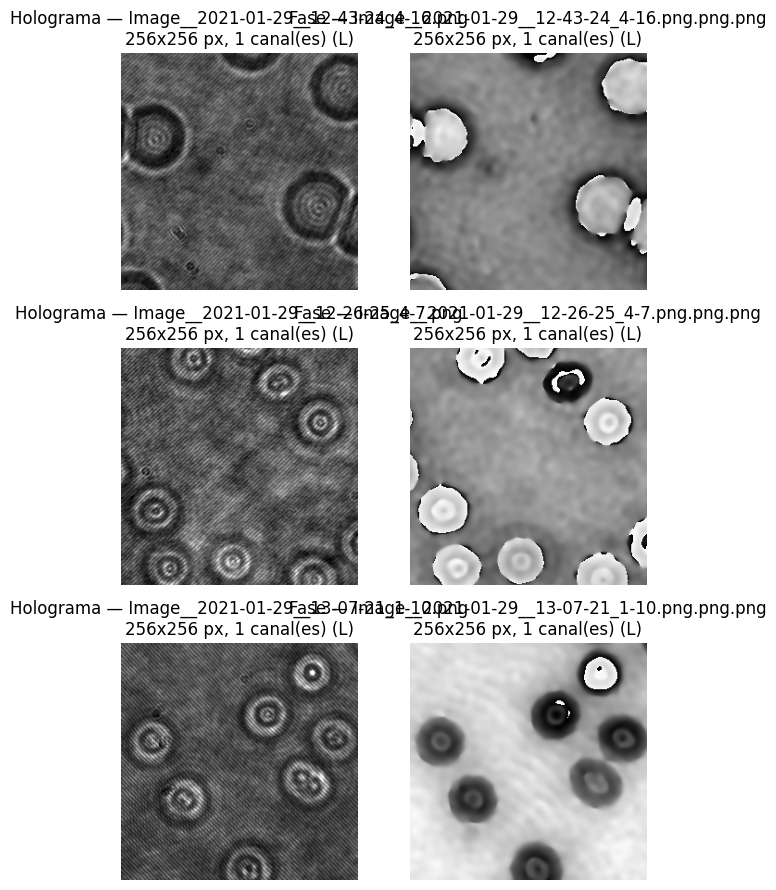

Tamaños de imagen encontrados en la muestra: {(256, 256)}
Canales — Holograms: {'L'}, Phase: {'L'}


In [5]:
import random

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

random.seed(42)

SPLIT = 'Training'
holo_dir = root / 'Holograms' / SPLIT
phase_dir = root / 'Phase' / SPLIT


def normalize_stem(filename):
    # Phase/ tiene algunos archivos con extensión duplicada ('foo.png.png')
    stem = filename
    while stem.endswith('.png'):
        stem = stem[:-4]
    return stem


def n_channels(img):
    return len(img.getbands())


holo_map = {normalize_stem(f.name): f.name for f in holo_dir.iterdir() if f.is_file()}
phase_map = {normalize_stem(f.name): f.name for f in phase_dir.iterdir() if f.is_file()}

common_stems = sorted(set(holo_map) & set(phase_map))
missing_in_phase = set(holo_map) - set(phase_map)
missing_in_holo = set(phase_map) - set(holo_map)

print(f'[{SPLIT}] pares completos: {len(common_stems)}')
print(f'[{SPLIT}] en Holograms sin fase: {len(missing_in_phase)}')
print(f'[{SPLIT}] en Phase sin holograma: {len(missing_in_holo)}')

sample_stems = random.sample(common_stems, 3)

fig, axes = plt.subplots(3, 2, figsize=(6, 9))
for i, stem in enumerate(sample_stems):
    holo_img = Image.open(holo_dir / holo_map[stem])
    phase_img = Image.open(phase_dir / phase_map[stem])

    axes[i, 0].imshow(holo_img, cmap='gray')
    axes[i, 0].set_title(
        f'Holograma — {holo_map[stem]}\n'
        f'{holo_img.size[0]}x{holo_img.size[1]} px, {n_channels(holo_img)} canal(es) ({holo_img.mode})'
    )
    axes[i, 0].axis('off')

    axes[i, 1].imshow(phase_img, cmap='gray')
    axes[i, 1].set_title(
        f'Fase — {phase_map[stem]}\n'
        f'{phase_img.size[0]}x{phase_img.size[1]} px, {n_channels(phase_img)} canal(es) ({phase_img.mode})'
    )
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

sizes = {Image.open(holo_dir / holo_map[s]).size for s in sample_stems}
sizes |= {Image.open(phase_dir / phase_map[s]).size for s in sample_stems}
print(f'Tamaños de imagen encontrados en la muestra: {sizes}')

holo_modes = {Image.open(holo_dir / holo_map[s]).mode for s in sample_stems}
phase_modes = {Image.open(phase_dir / phase_map[s]).mode for s in sample_stems}
print(f'Canales — Holograms: {holo_modes}, Phase: {phase_modes}')

## 5. Alineamiento estructural (overlay + SSIM)

Superposición con transparencia de holograma y fase para los 3 pares anteriores, junto con su
índice de similitud estructural (SSIM). El SSIM aquí no mide "la misma escena" (holograma y fase
son modalidades distintas), sino cuánta estructura espacial comparten dos señales que vienen del
mismo campo de visión — útil como chequeo rápido de que el recorte/alineación del par es correcto.

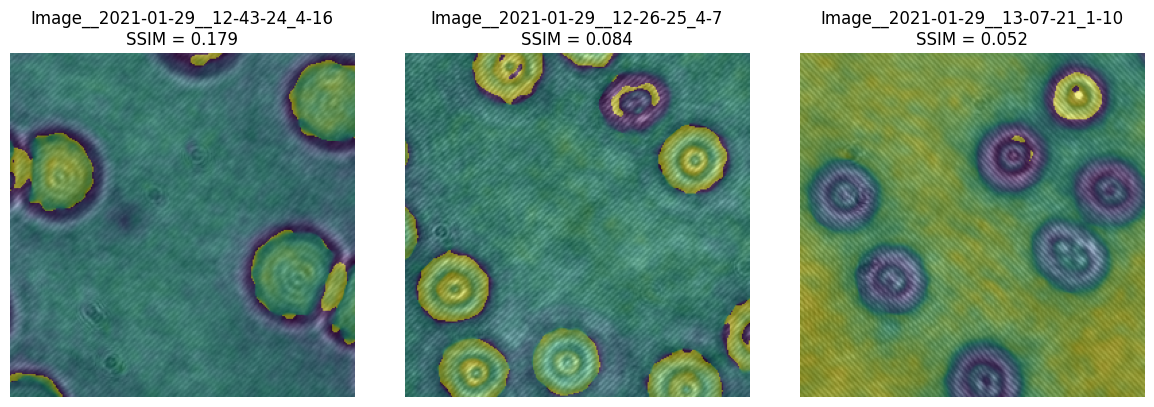

In [6]:
from skimage.metrics import structural_similarity as ssim

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for i, stem in enumerate(sample_stems):
    holo_arr = np.array(Image.open(holo_dir / holo_map[stem]).convert('L'), dtype=np.float32)
    phase_arr = np.array(Image.open(phase_dir / phase_map[stem]).convert('L'), dtype=np.float32)

    assert holo_arr.shape == phase_arr.shape, f'{stem}: tamaños distintos entre holograma y fase'

    score = ssim(holo_arr, phase_arr, data_range=255)

    axes[i].imshow(holo_arr, cmap='gray')
    axes[i].imshow(phase_arr, cmap='viridis', alpha=0.5)
    axes[i].set_title(f'{stem}\nSSIM = {score:.3f}')
    axes[i].axis('off')

plt.tight_layout()
plt.show()

## 6. Distribución de valores de píxel por carpeta

Comparación lado a lado de la distribución de valores de píxel entre `Holograms/` y `Phase/`
(las dos mitades del dataset), sobre una muestra aleatoria de 500 imágenes por carpeta — recorrer
las 36.864 imágenes completas no aporta precisión adicional a este chequeo y es mucho más lento.

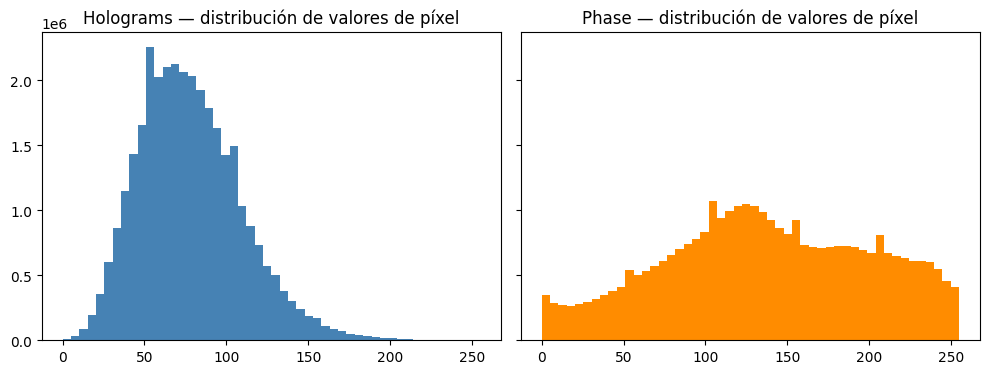

Holograms: media=78.2, std=31.5
Phase:     media=137.2, std=62.9


In [7]:
N_SAMPLE = 500
sample_stems_hist = random.sample(common_stems, N_SAMPLE)

holo_values = np.concatenate([
    np.array(Image.open(holo_dir / holo_map[s]), dtype=np.uint8).ravel() for s in sample_stems_hist
])
phase_values = np.concatenate([
    np.array(Image.open(phase_dir / phase_map[s]), dtype=np.uint8).ravel() for s in sample_stems_hist
])

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
axes[0].hist(holo_values, bins=50, color='steelblue')
axes[0].set_title('Holograms — distribución de valores de píxel')
axes[1].hist(phase_values, bins=50, color='darkorange')
axes[1].set_title('Phase — distribución de valores de píxel')
plt.tight_layout()
plt.show()

print(f'Holograms: media={holo_values.mean():.1f}, std={holo_values.std():.1f}')
print(f'Phase:     media={phase_values.mean():.1f}, std={phase_values.std():.1f}')

## 7. Casos extremos en la distribución de valores

Sobre la misma muestra de 500 imágenes por carpeta: se calcula el valor medio de píxel por imagen
y se marca como caso extremo aquella cuyo z-score (respecto a la media de la muestra) supera 3 en
valor absoluto.

In [ ]:
holo_means = np.array([
    np.array(Image.open(holo_dir / holo_map[s]), dtype=np.float32).mean() for s in sample_stems_hist
])
phase_means = np.array([
    np.array(Image.open(phase_dir / phase_map[s]), dtype=np.float32).mean() for s in sample_stems_hist
])


def report_outliers(means, stems, label, z_thresh=3.0):
    mu, sigma = means.mean(), means.std()
    z = (means - mu) / sigma
    outlier_idx = np.where(np.abs(z) > z_thresh)[0]
    print(f'{label}: media={mu:.1f}, std={sigma:.1f}, outliers (|z|>{z_thresh}): {len(outlier_idx)}')
    for idx in outlier_idx:
        print(f'  {stems[idx]}  mean={means[idx]:.1f}  z={z[idx]:.2f}')


report_outliers(holo_means, sample_stems_hist, 'Holograms')
report_outliers(phase_means, sample_stems_hist, 'Phase')

Holograms: media=78.2, std=15.5, outliers (|z|>3.0): 6
  Image__2021-01-29__12-27-12_2-5  mean=127.6  z=3.20
  Image__2021-01-29__13-22-51_4-12  mean=139.0  z=3.93
  Image__2021-01-29__12-47-43_2-6  mean=136.0  z=3.74
  Image__2021-01-28__15-49-02_4-1  mean=161.3  z=5.37
  Image__2021-01-28__15-49-38_4-9  mean=152.7  z=4.82
  Image__2021-01-28__15-49-28_4-10  mean=133.4  z=3.57
Phase: media=137.2, std=27.1, outliers (|z|>3.0): 2
  Image__2021-01-29__13-33-52_3-9  mean=223.5  z=3.18
  Image__2021-01-29__12-55-57_4-7  mean=226.8  z=3.30


: 